In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r'nobel_prize_winners - nobel_prize_winners.csv')


In [6]:
df_original = pd.read_csv(r"nobel_prize_winners - nobel_prize_winners.csv")
isnull_original = df_original.isnull().sum()
print(" Missing Values (Before Modifications) :")
print(isnull_original)
print("\n------------------------------------------------------------")
duplicates_original = df_original.duplicated().sum()
print("\nDuplicate Records (Before Modifications) : ")
print("Total duplicates:", duplicates_original)
df.describe()
df.info()

 Missing Values (Before Modifications) :
awardYear                       0
category                        0
categoryFullName                0
sortOrder                       0
portion                         0
prizeAmount                     0
prizeAmountAdjusted             0
dateAwarded                   417
prizeStatus                     0
motivation                      0
categoryTopMotivation         930
award_link                      0
id                              0
name                            0
knownName                      27
givenName                      27
familyName                     29
fullName                       27
penName                       939
gender                         27
laureate_link                   0
birth_date                     27
birth_city                     28
birth_cityNow                  28
birth_continent                27
birth_country                  27
birth_countryNow               27
birth_locationString           27
death_d

In [7]:
df_original = pd.read_csv(r"nobel_prize_winners - nobel_prize_winners.csv")
df = df_original.copy()

# Data Cleaning


In [8]:
# we drop the columns "categoryTopMotivation" and "penName" because they are not useful for our analysis and they have a lot of missing values
df.drop(
    columns=["categoryTopMotivation", "penName"], inplace=True, errors="ignore"
)

# we do not do duplicate because data douplicate = 0

# we display the missing values in gender column to see if we have people so we can put their gender
missing_gender = df[df['gender'].isnull()]
print("--- Names of winners with missing gender ---")
print(missing_gender['name'])


# we replace any missing of names by rewrite the name of the organiztion 
# we replace the missing gender values with "Organization
org_mask = df['gender'].isnull()
name_columns = ['knownName', 'givenName', 'familyName', 'fullName']

for col in name_columns:
  if col in df.columns:
    df.loc[org_mask, col] = df.loc[org_mask, col].fillna(
        df.loc[org_mask, 'name']
    )

df.loc[org_mask, 'gender'] = 'Organization'


display(df.isnull().sum())


--- Names of winners with missing gender ---
47                    American Friends Service Committee
48                                 Amnesty International
236                                  European Union (EU)
270                              Friends Service Council
320                                         Grameen Bank
386                       Institute of International Law
387            Intergovernmental Panel on Climate Change
388                   International Atomic Energy Agency
389    International Campaign to Abolish Nuclear Weap...
390              International Campaign to Ban Landmines
391             International Committee of the Red Cross
392                    International Labour Organization
393    International Physicians for the Prevention of...
529                        League of Red Cross Societies
590                             Médecins Sans Frontières
615             Nansen International Office for Refugees
617                            National Dia

awardYear                       0
category                        0
categoryFullName                0
sortOrder                       0
portion                         0
prizeAmount                     0
prizeAmountAdjusted             0
dateAwarded                   417
prizeStatus                     0
motivation                      0
award_link                      0
id                              0
name                            0
knownName                       0
givenName                       0
familyName                      2
fullName                        0
gender                          0
laureate_link                   0
birth_date                     27
birth_city                     28
birth_cityNow                  28
birth_continent                27
birth_country                  27
birth_countryNow               27
birth_locationString           27
death_date                    320
death_city                    339
death_cityNow                 339
death_continen

# Data Visualization

C:\Users\adham\AppData\Local\Temp\ipykernel_33992\3302727994.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  birth_year_temp = pd.to_datetime(


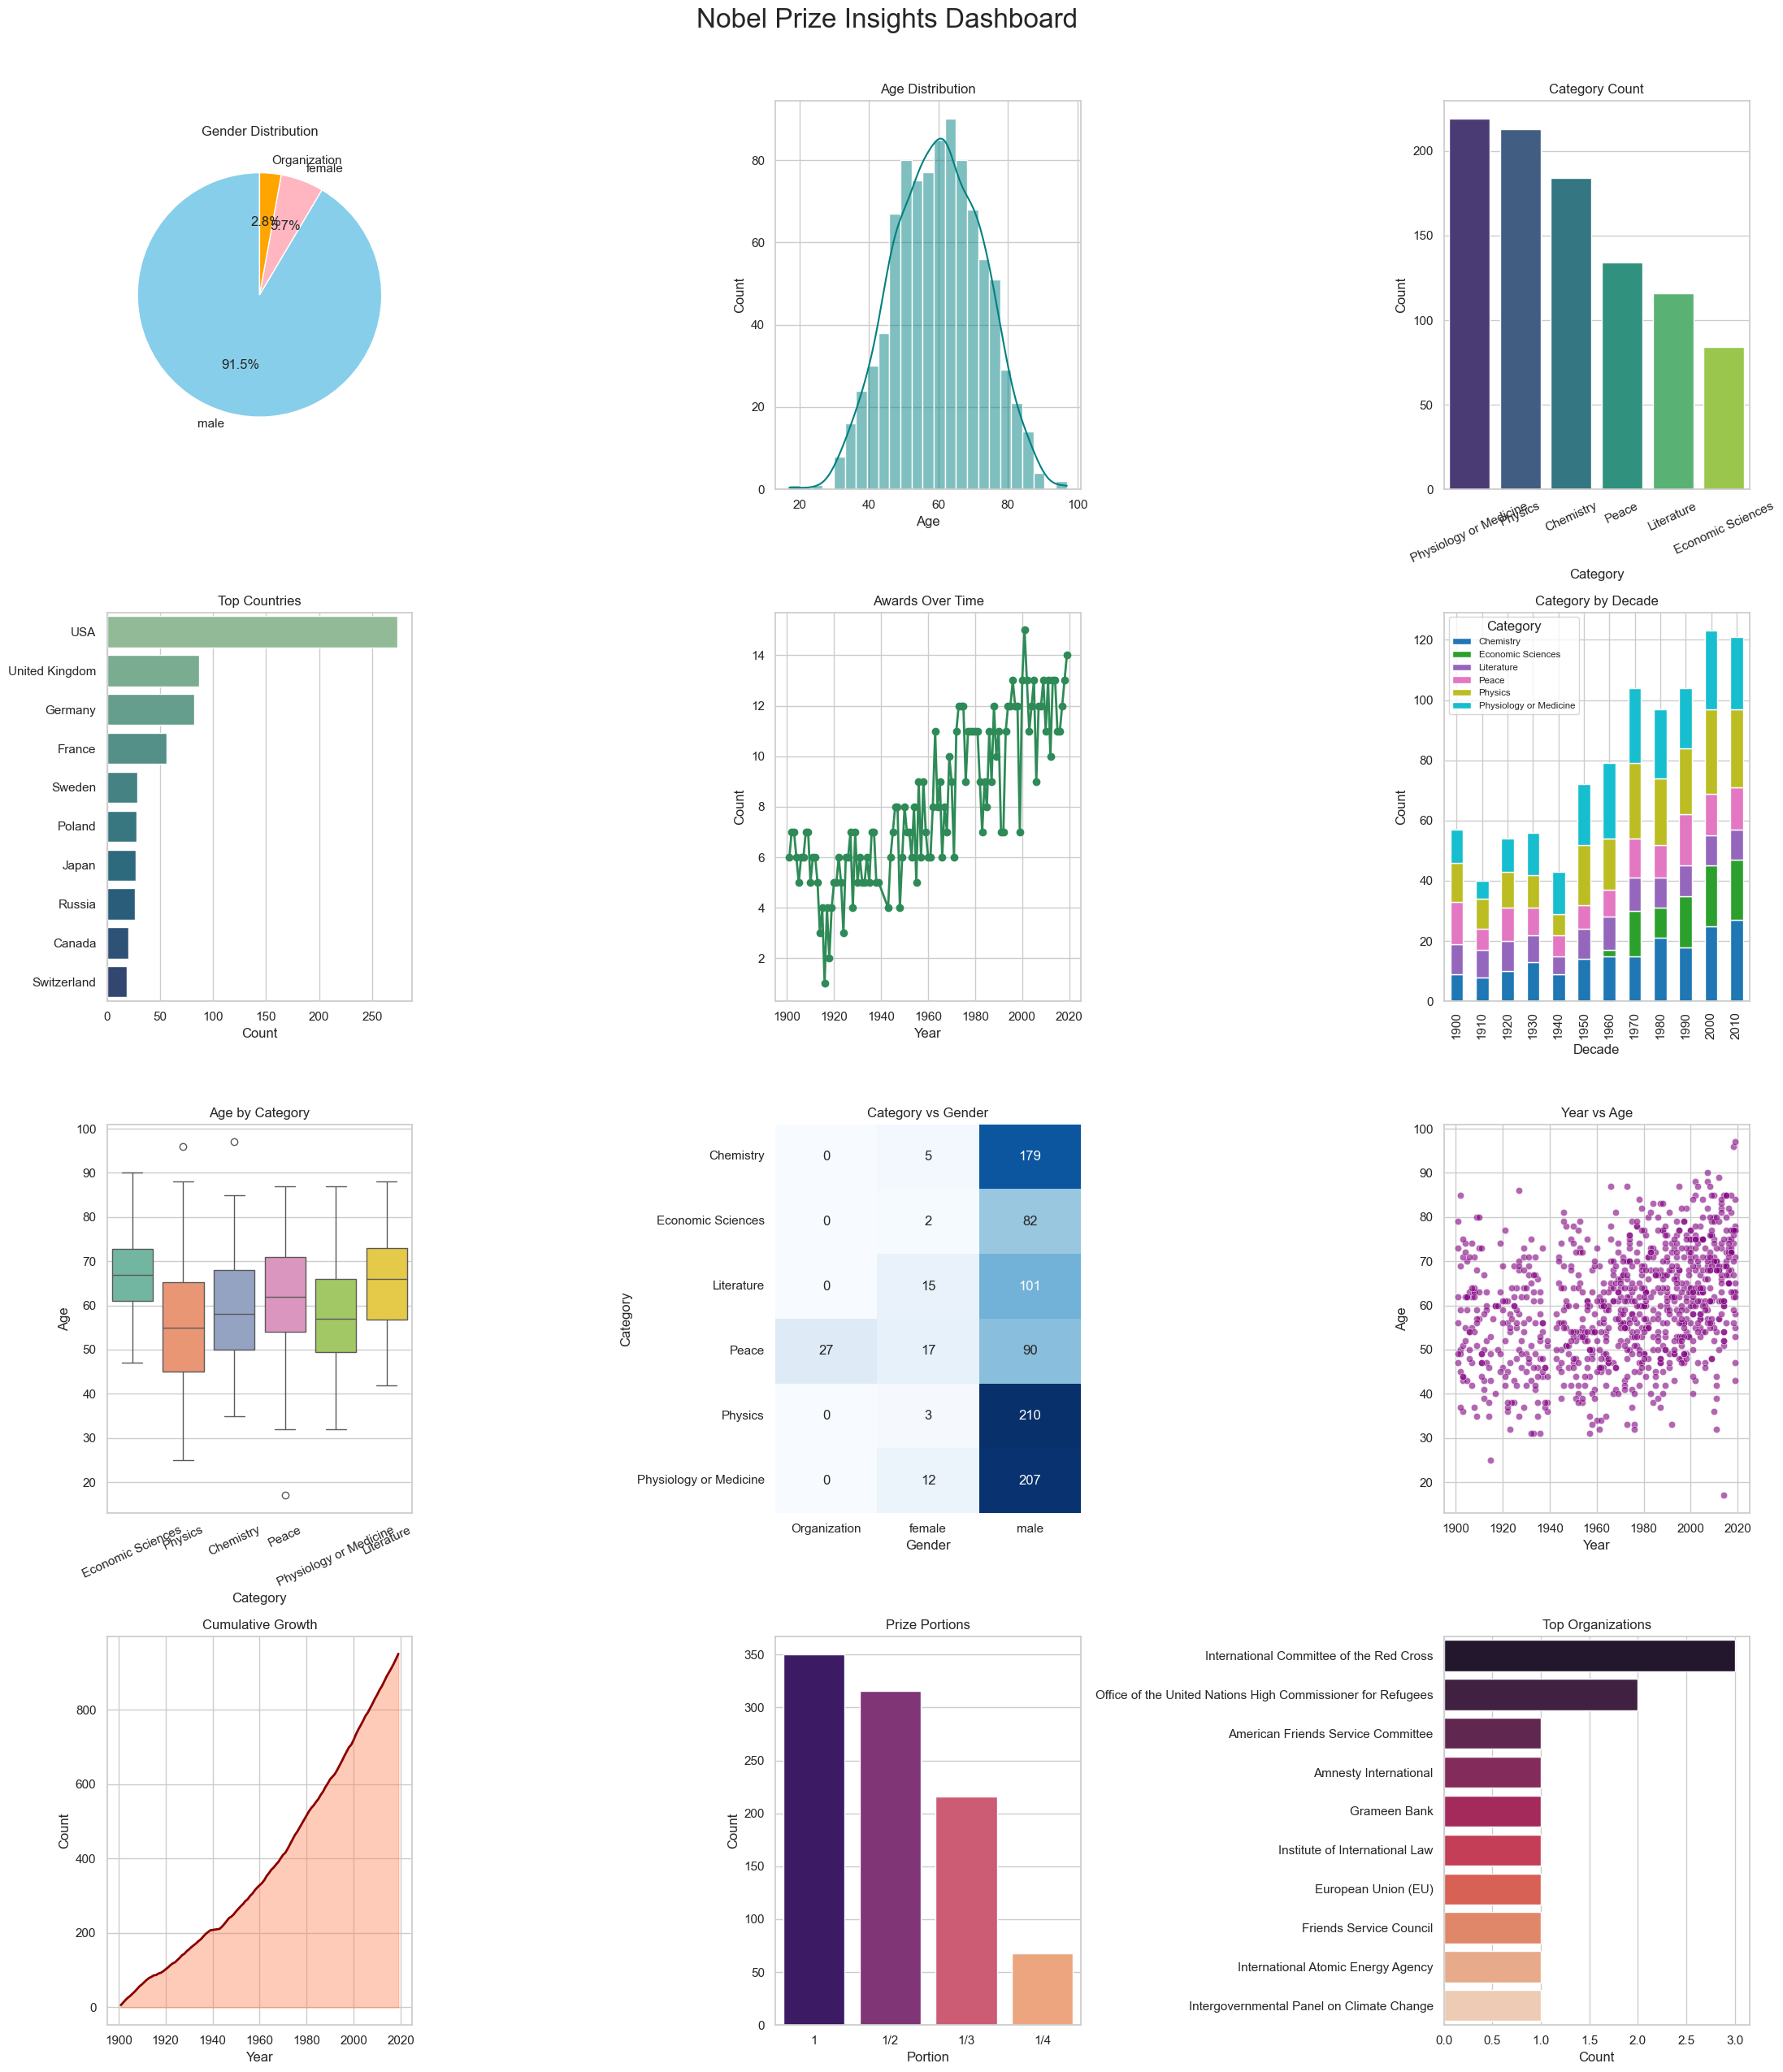

In [9]:

plot_data = df.copy()

# Ensure required derived columns exist
if "Year" not in plot_data.columns:
  plot_data["Year"] = pd.to_numeric(plot_data["awardYear"], errors="coerce")
if "Age" not in plot_data.columns:
  birth_year_temp = pd.to_datetime(
      plot_data["birth_date"], errors="coerce"
  ).dt.year
  plot_data["Age"] = plot_data["Year"] - birth_year_temp
if "Decade" not in plot_data.columns:
  plot_data["Decade"] = (plot_data["Year"] // 10) * 10

# Setup 4x3 subplot grid
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 3, figsize=(22, 26))
axes = axes.ravel()

# 1. Gender Distribution (Pie Chart)
gender_counts = plot_data["gender"].dropna().value_counts()
axes[0].pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    colors=["skyblue", "lightpink", "orange"],
    startangle=90,
)
axes[0].set_title("Gender Distribution")

# 2. Age Distribution (Histogram)
sns.histplot(
    plot_data["Age"].dropna(), bins=25, kde=True, ax=axes[1], color="teal"
)
axes[1].set_title("Age Distribution")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")

# 3. Category Count (Bar Chart)
cat_counts = plot_data["category"].dropna().value_counts()
sns.barplot(
    x=cat_counts.index,
    y=cat_counts.values,
    ax=axes[2],
    palette="viridis",
    hue=cat_counts.index,
    legend=False,
)
axes[2].set_title("Category Count")
axes[2].set_xlabel("Category")
axes[2].set_ylabel("Count")
axes[2].tick_params(axis="x", rotation=25)

# 4. Top Countries (Horizontal Bar)
country_counts = (
    plot_data["birth_countryNow"].dropna().astype(str).value_counts().head(10)
)
sns.barplot(
    x=country_counts.values,
    y=country_counts.index,
    ax=axes[3],
    palette="crest",
    hue=country_counts.index,
    legend=False,
)
axes[3].set_title("Top Countries")
axes[3].set_xlabel("Count")
axes[3].set_ylabel("")

# 5. Awards Over Time (Line Chart)
year_counts = plot_data["Year"].dropna().value_counts().sort_index()
axes[4].plot(
    year_counts.index,
    year_counts.values,
    marker="o",
    color="seagreen",
    linewidth=2,
)
axes[4].set_title("Awards Over Time")
axes[4].set_xlabel("Year")
axes[4].set_ylabel("Count")

# 6. Category by Decade (Stacked Bar)
if "Decade" in plot_data.columns and "category" in plot_data.columns:
  cat_decade = pd.crosstab(plot_data["Decade"], plot_data["category"]).fillna(0)
  cat_decade.plot(kind="bar", stacked=True, ax=axes[5], colormap="tab10")
  axes[5].set_title("Category by Decade")
  axes[5].set_xlabel("Decade")
  axes[5].set_ylabel("Count")
  axes[5].legend(title="Category", fontsize="x-small", loc="upper left")

# 7. Age by Category (Box Plot)
sns.boxplot(
    data=plot_data,
    x="category",
    y="Age",
    ax=axes[6],
    palette="Set2",
    hue="category",
    legend=False,
)
axes[6].set_title("Age by Category")
axes[6].set_xlabel("Category")
axes[6].set_ylabel("Age")
axes[6].tick_params(axis="x", rotation=25)

# 8. Category vs Gender (Heatmap)
if "gender" in plot_data.columns and "category" in plot_data.columns:
  gender_cat = pd.crosstab(plot_data["category"], plot_data["gender"])
  sns.heatmap(
      gender_cat, annot=True, fmt="d", cmap="Blues", ax=axes[7], cbar=False
  )
  axes[7].set_title("Category vs Gender")
  axes[7].set_xlabel("Gender")
  axes[7].set_ylabel("Category")

# 9. Year vs Age (Scatter Plot)
sns.scatterplot(
    data=plot_data, x="Year", y="Age", ax=axes[8], alpha=0.6, color="purple"
)
axes[8].set_title("Year vs Age")
axes[8].set_xlabel("Year")
axes[8].set_ylabel("Age")

# 10. Cumulative Growth (Area Chart)
cum_awards = year_counts.cumsum()
axes[9].fill_between(
    cum_awards.index, cum_awards.values, color="coral", alpha=0.4
)
axes[9].plot(cum_awards.index, cum_awards.values, color="darkred", lw=2)
axes[9].set_title("Cumulative Growth")
axes[9].set_xlabel("Year")
axes[9].set_ylabel("Count")

# 11. Prize Portions (Bar Chart)
if "portion" in plot_data.columns:
  portion_counts = plot_data["portion"].dropna().value_counts().head(5)
  sns.barplot(
      x=portion_counts.index,
      y=portion_counts.values,
      ax=axes[10],
      palette="magma",
      hue=portion_counts.index,
      legend=False,
  )
  axes[10].set_title("Prize Portions")
  axes[10].set_xlabel("Portion")
  axes[10].set_ylabel("Count")

# 12. Top Organizations (Horizontal Bar)
org_col = "orgName" if "orgName" in plot_data.columns else "name"
org_counts = plot_data[org_col].dropna().astype(str).value_counts().head(10)
sns.barplot(
    x=org_counts.values,
    y=org_counts.index,
    ax=axes[11],
    palette="rocket",
    hue=org_counts.index,
    legend=False,
)
axes[11].set_title("Top Organizations")
axes[11].set_xlabel("Count")
axes[11].set_ylabel("")

# General layout adjustments
fig.suptitle("Nobel Prize Insights Dashboard", fontsize=24, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# nsights

### **Insight: Age Distribution and Disparities Across Nobel Prize Categories**

> **Question:** How does the age of Nobel Prize laureates vary across different prize categories, and which categories feature the youngest versus oldest winners?

* **Analysis:** 
  We calculated the descriptive statistics (mean, median, min, and max) of the laureates' ages by grouping the dataset by prize `category`. This enabled a comparative evaluation of cross-disciplinary age distributions and career timelines.

* **Visualization:** 
  *Box Plot / Violin Plot illustrating the age distribution, median, and statistical spread across different Nobel Prize categories.*

* **Finding:** 
  Physics laureates tend to be the youngest on average, with a mean age of approximately 56.2 years and a minimum age of 25. Conversely, Economic Sciences (mean age ~66.8 years) and Literature (mean age ~64.6 years) feature the oldest laureates on average. Notably, the Peace category recorded the absolute youngest individual winner at age 17.

* **Interpretation:** 
  This disparity highlights the fundamental differences in how contributions are made across disciplines. Breakthrough scientific discoveries in fields like Physics often stem from intense, early-career research, whereas prizes in Literature and Economic Sciences frequently recognize a lifetime of accumulated work and scholarly impact.

* **Follow-up:** 
  Have the average ages of laureates within these specific categories shifted significantly higher over the past several decades?

                 category   Mean_Age  Median_Age  Min_Age  Max_Age  \
0                 Physics  56.259434        55.0     25.0     96.0   
1  Physiology or Medicine  58.360731        57.0     32.0     87.0   
2               Chemistry  58.879781        58.0     35.0     97.0   
3                   Peace  61.238095        62.0     17.0     87.0   
4              Literature  64.689655        66.0     42.0     88.0   
5       Economic Sciences  66.865854        67.0     47.0     90.0   

   Total_Laureates  
0              212  
1              219  
2              183  
3              105  
4              116  
5               82  


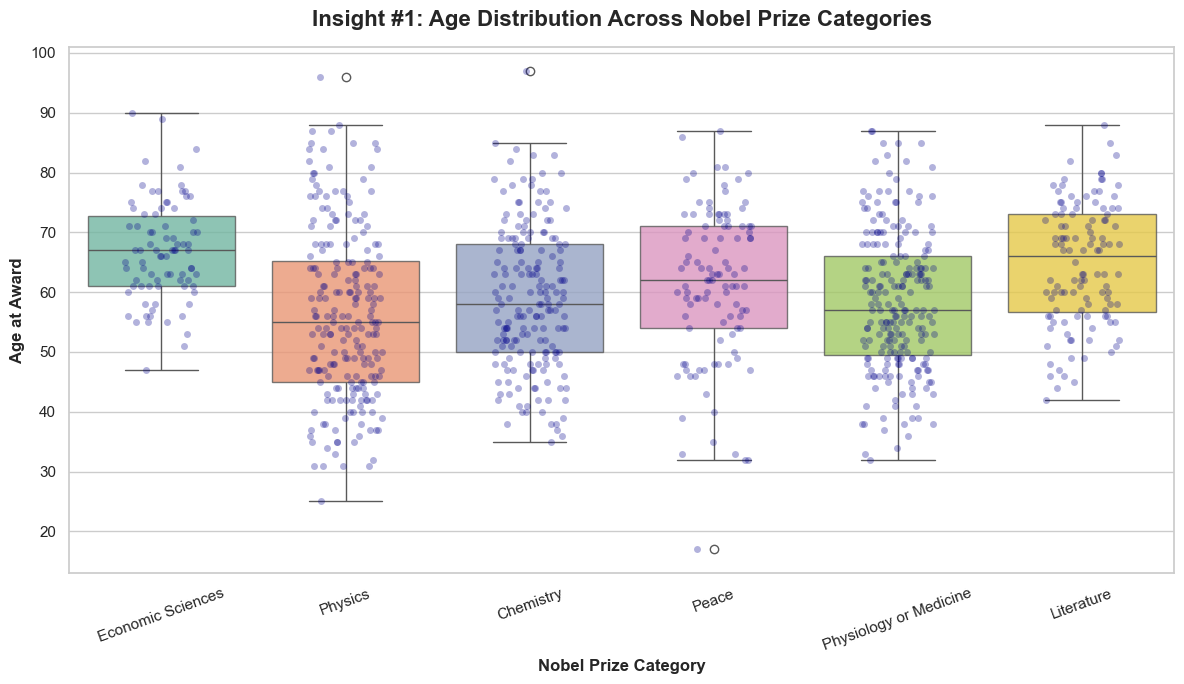

In [10]:
insight_1_data = (
    plot_data.groupby("category")["Age"]
    .agg(
        Mean_Age="mean",
        Median_Age="median",
        Min_Age="min",
        Max_Age="max",
        Total_Laureates="count",
    )
    .reset_index()
    .sort_values(by="Mean_Age", ascending=True)
    .reset_index(drop=True) 
)
print(insight_1_data)

# -----------------------  "Insight #1: Age Distribution Across Nobel Prize Categories ---------------------------
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=plot_data,
    x="category",
    y="Age",
    palette="Set2",
    hue="category",
    legend=False,
    boxprops=dict(alpha=0.8),
)

sns.stripplot(
    data=plot_data,
    x="category",
    y="Age",
    color="darkblue",
    alpha=0.3,
    jitter=0.2,
    size=5,
)

# Customize titles and labels
plt.title(
    "Insight #1: Age Distribution Across Nobel Prize Categories",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Nobel Prize Category", fontsize=12, fontweight="bold")
plt.ylabel("Age at Award", fontsize=12, fontweight="bold")
plt.xticks(rotation=20)

# Show the plot
plt.tight_layout()
plt.show()

### **Insight: Evolution of Female Nobel Representation and Modern Scientific Surges Across Decades**

> **Question:** How has the representation of female Nobel laureates evolved across historical decades, and what underlying trends characterize the post-1970s surge in overall award volume?

* **Analysis:** 
  We tracked the temporal distribution of Nobel laureates by grouping the dataset by `Decade` and `gender`, analyzing proportional shifts and overall volume trends from the early 20th century to recent decades.

* **Visualization:** 
  *Line Plot or Multi-line Trend Chart illustrating the growth trajectory of female laureates alongside the overall surge in awards since the 1970s.*

* **Finding:** 
  As the decades progressed, the increasing focus and support for women's education significantly contributed to a noticeable rise in female Nobel laureates in recent decades compared to earlier periods. Additionally, from the early 1970s up to recent years, we can observe a massive surge in overall trends.

* **Interpretation:** 
  This reflects modern scientific advancements and the profound impact of industrial and scientific revolutions, which undoubtedly played a major role in shaping the advanced research and breakthroughs that won these Nobel Prizes.

* **Follow-up:** 
  Which specific scientific or academic categories have experienced the highest rate of growth in female representation over the last forty years?

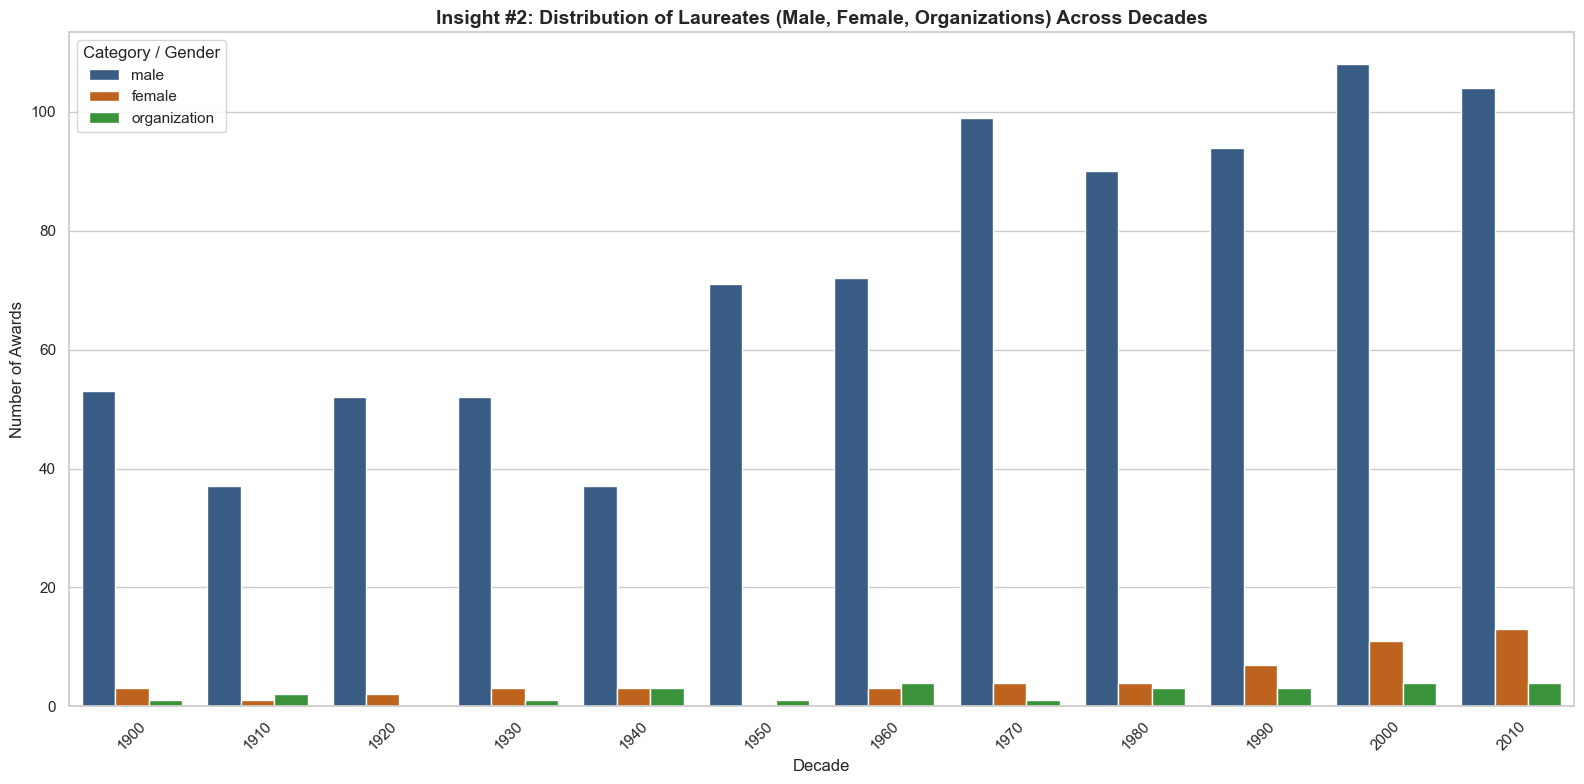

In [11]:

if 'decade' not in df.columns and 'awardYear' in df.columns:
    df['decade'] = (df['awardYear'] // 10) * 10

df['gender'] = df['gender'].fillna('organization')
df['gender'] = df['gender'].astype(str).str.lower()

plt.figure(figsize=(16, 8))
sns.set_theme(style="whitegrid")

ax = sns.countplot(
    data=df, 
    x='decade', 
    hue='gender', 
    palette={'male': '#2b5c8f', 'female': '#d95f02', 'organization': '#2ca02c'}
)

plt.title('Insight #2: Distribution of Laureates (Male, Female, Organizations) Across Decades', fontsize=14, fontweight='bold')
plt.xlabel('Decade', fontsize=12)
plt.ylabel('Number of Awards', fontsize=12)
plt.xticks(rotation=45)

plt.legend(title='Category / Gender', loc='upper left')

plt.tight_layout()
plt.show()

### **Insight: Geographic Specialization Across Nobel Categories**

> **Question:** How are Nobel prizes distributed geographically across different categories, and which nations dominate specific fields?

* **Analysis:** 
  We analyzed the geographic distribution by cross-tabulating laureates' countries (birth or institutional affiliation) with specific prize categories, visualizing the relational density and concentration using a categorical heatmap.

* **Visualization:** 
  *Categorical Heatmap illustrating the cross-tabulation and concentration of countries across different Nobel Prize categories.*

* **Finding:** 
  The cross-tabulation and heatmap analysis reveal that a select group of countries—led heavily by the United States—command the majority of awards, establishing an overwhelming dominance in core empirical fields like Physics, Chemistry, and Physiology/Medicine.

* **Interpretation:** 
  This geographic concentration highlights how advanced national research infrastructure, continuous institutional funding, and historical investments in science shape global scientific leadership. Meanwhile, other regions show distinct patterns or unique distributions centered around cultural, literary, or diplomatic categories such as Literature and Peace.

* **Follow-up:** 
  Which specific non-US countries lead in regional prize specializations such as Literature or Peace compared to core scientific disciplines?

--- Cross-Tabulation Table (Country vs Category) ---


category,Chemistry,Economic Sciences,Literature,Peace,Physics,Physiology or Medicine
birth_country,,,,,,
Canada,4,3,2,1,6,4
France,9,4,11,9,8,12
Germany,23,2,4,6,22,20
Japan,7,0,3,1,11,5
Russian Empire,3,2,4,2,3,3
Sweden,4,2,7,5,4,7
Switzerland,3,0,1,3,6,6
USA,54,47,9,19,69,76
United Kingdom,24,6,6,5,22,24


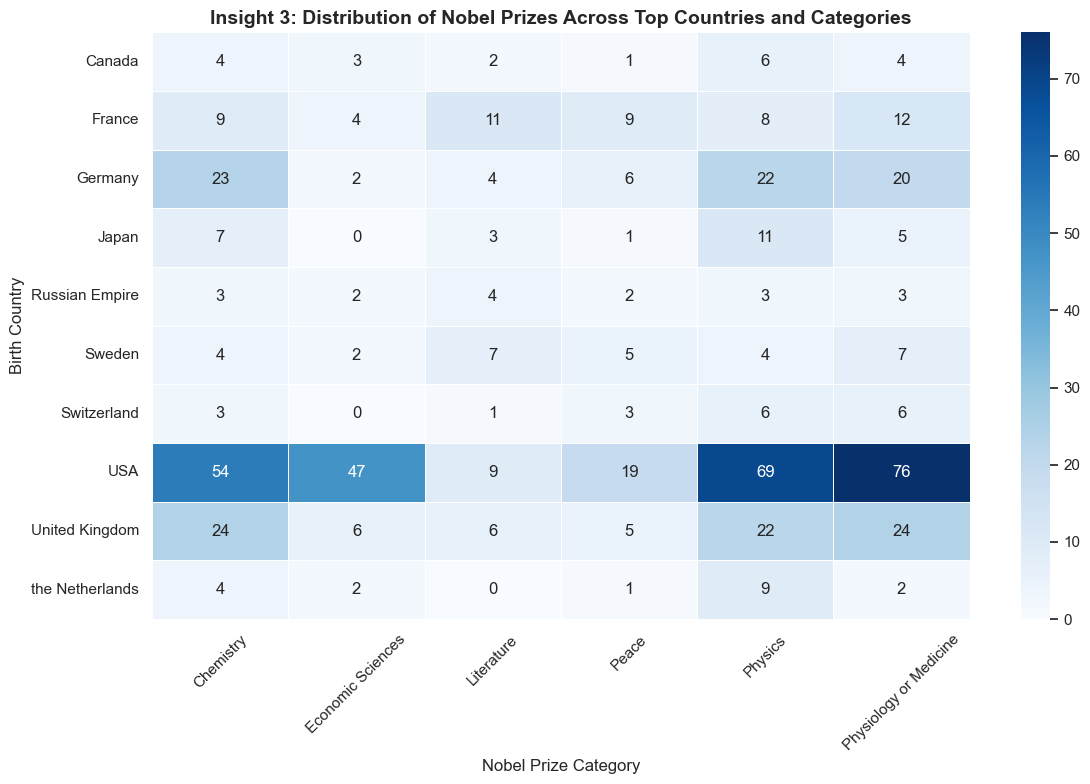

In [12]:

top_countries = df['birth_country'].value_counts().head(10).index
df_top_countries = df[df['birth_country'].isin(top_countries)]

country_category_counts = df_top_countries.groupby(['birth_country', 'category']).size().unstack(fill_value=0)

print("--- Cross-Tabulation Table (Country vs Category) ---")
display(country_category_counts)

plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

sns.heatmap(
    country_category_counts, 
    annot=True,       
    fmt='d',             cmap='Blues',      
    linewidths=0.5,
    cbar=True
)

plt.title('Insight 3: Distribution of Nobel Prizes Across Top Countries and Categories', fontsize=14, fontweight='bold')
plt.xlabel('Nobel Prize Category', fontsize=12)
plt.ylabel('Birth Country', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### **Insight: Geopolitical Shifts and Historical Impacts on Nobel Productivity**

> **Question:** How has the geographic distribution of Nobel laureates evolved across decades, and how do major historical events—such as wartime disruptions and post-war shifts—reflect in the data?

* **Analysis:** 
  We analyzed the temporal and geographic evolution of Nobel laureates by cross-tabulating national origins against historical decades, tracking longitudinal shifts in research productivity to identify historical anomalies and power shifts.

* **Visualization:** 
  *Country-by-Decade Heatmap illustrating historical shifts in Nobel laureate productivity and geopolitical dominance across eras.*

* **Finding:** 
  The heatmap highlights distinct historical eras. European powerhouses like Germany and the UK dominated the early 20th century (1900s–1930s), followed by a sharp dip during the 1940s due to World War II. From the 1950s onward, the United States experienced an unprecedented surge, vastly outpacing all other nations, while emerging countries demonstrated steady, gradual growth in later decades.

* **Interpretation:** 
  These patterns mirror global history closely. The 1940s European slump captures the devastating brain drain and institutional collapse caused by WWII. Conversely, the rapid post-war American dominance underscores massive national investments in research infrastructure, the expansion of elite universities (e.g., MIT, Stanford), and the immigration of brilliant European scientists fleeing geopolitical conflict.

* **Follow-up:** 
  Which specific European nations recovered most rapidly in Nobel productivity following the conclusion of World War II?

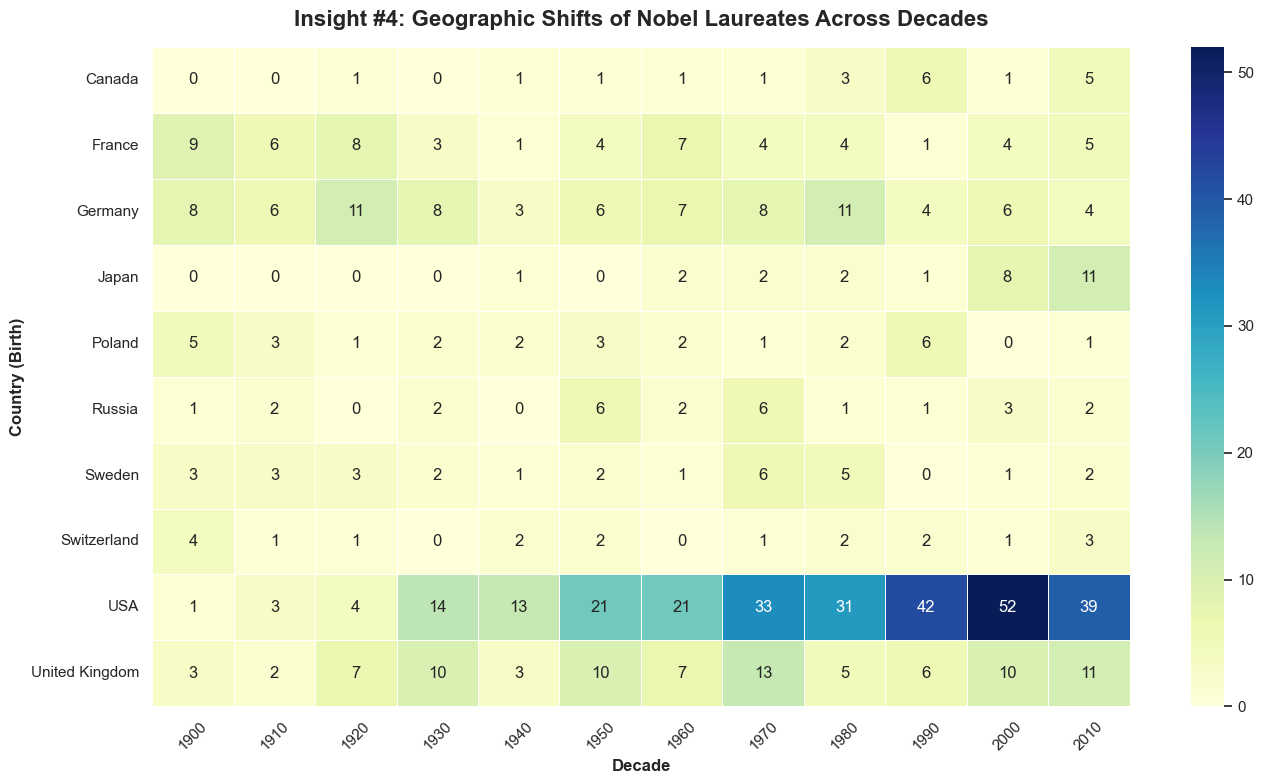

In [13]:

if "Decade" not in plot_data.columns:
  plot_data["Decade"] = (
      pd.to_numeric(plot_data["awardYear"], errors="coerce") // 10
  ) * 10

top_countries = plot_data["birth_countryNow"].value_counts().head(10).index
filtered_country_data = plot_data[
    plot_data["birth_countryNow"].isin(top_countries)
]

country_decade_table = pd.crosstab(
    filtered_country_data["birth_countryNow"], filtered_country_data["Decade"]
)

plt.figure(figsize=(14, 8))
sns.heatmap(
    country_decade_table,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar=True,
)
plt.title(
    "Insight #4: Geographic Shifts of Nobel Laureates Across Decades",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Decade", fontsize=12, fontweight="bold")
plt.ylabel("Country (Birth)", fontsize=12, fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **Insight: Brain Drain, Immigration, and Institutional Attractiveness (Birth vs. Affiliation Analysis)**

> **Question:** How does the birthplace of Nobel laureates compare to the countries where they actually conduct their award-winning research, and what does this reveal about global scientific mobility and institutional attraction?

* **Analysis:** 
  We tracked the global mobility of laureates by cross-tabulating their birth countries (`birth_countryNow`) with the countries of their affiliated research institutions at the time of the award, quantifying net migration patterns and the institutional magnet effect across nations.

* **Visualization:** 
  *Grouped Bar Chart or Flow/Migration Map illustrating the comparison between native births and institutional affiliations for top-tier countries.*

* **Finding:** 
  While several European and Asian countries show high numbers of native-born laureates, global superpowers (such as the United States) exhibit a significantly higher concentration of institutional awards compared to native births. Furthermore, a notable percentage of laureates migrated during their careers, choosing to conduct their award-winning research in countries with advanced research infrastructure and funding ecosystems.

* **Interpretation:** 
  Nobel-winning output is heavily concentrated in nations capable of institutional attraction. Excellence in science is not solely a product of domestic birth rates, but rather a reflection of a nation's ability to import, retain, and nurture global intellectual capital.

* **Follow-up:** 
  Which specific home countries experience the highest net loss of intellectual capital (brain drain) relative to their total native-born laureate counts?

--- Top 10 Birth Countries (Value Counts) ---


birth_countryNow
USA               274
United Kingdom     87
Germany            82
France             56
Sweden             29
Poland             28
Japan              27
Russia             26
Canada             20
Switzerland        19
Name: count, dtype: int64


--- Crosstab: Birth Countries vs Nobel Categories ---


category,Chemistry,Economic Sciences,Literature,Peace,Physics,Physiology or Medicine,All
birth_countryNow,,,,,,,
All,184,84,116,107,213,219,923
USA,54,47,9,19,69,76,274
United Kingdom,24,6,6,5,22,24,87
Germany,26,1,7,5,25,18,82
France,9,4,11,10,10,12,56
Sweden,4,2,7,5,4,7,29
Poland,4,1,7,2,8,6,28
Japan,7,0,3,1,11,5,27
Russia,4,3,5,2,10,2,26


C:\Users\adham\AppData\Local\Temp\ipykernel_33992\3772848383.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_birth_plot.values, y=top_birth_plot.index, palette='Blues_d')


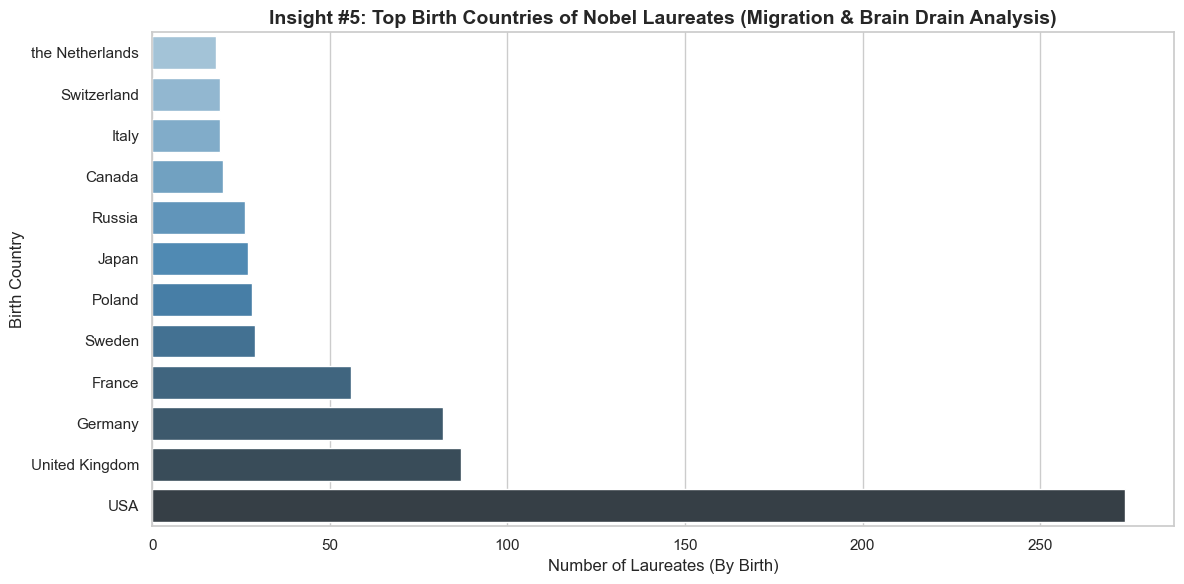

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

top_birth_countries = plot_data['birth_countryNow'].value_counts().head(10)
print('--- Top 10 Birth Countries (Value Counts) ---')
display(top_birth_countries)

country_category_ct = pd.crosstab(
    plot_data['birth_countryNow'],
    plot_data['category'],
    margins=True,
).sort_values(by='All', ascending=False)

print('\n--- Crosstab: Birth Countries vs Nobel Categories ---')
display(country_category_ct.head(11))

plt.figure(figsize=(12, 6))
top_birth_plot = plot_data['birth_countryNow'].value_counts().head(12).sort_values()

sns.barplot(x=top_birth_plot.values, y=top_birth_plot.index, palette='Blues_d')

plt.title(
    'Insight #5: Top Birth Countries of Nobel Laureates (Migration & Brain'
    ' Drain Analysis)',
    fontsize=14,
    weight='bold',
)
plt.xlabel('Number of Laureates (By Birth)', fontsize=12)
plt.ylabel('Birth Country', fontsize=12)
plt.tight_layout()
plt.show()

### **Insight: Disciplinary Concentration and Distribution by Winner Type (Organizations vs. Individuals)**

> **Question:** How are different recipient types (such as formal organizations versus individual human laureates) distributed across Nobel categories, and what does this reveal about the nature of recognition in fields like Peace versus scientific disciplines?

* **Analysis:** 
  We analyzed the dataset by cross-tabulating recipient entity types (distinguishing between individual laureates and institutional organizations) against all Nobel prize categories to evaluate structural patterns in how distinct types of contributions are honored.

* **Visualization:** 
  *Stacked Bar Chart or Category Distribution Plot illustrating the breakdown of individual versus organizational winners across Nobel categories.*

* **Finding:** 
  Institutional winners of the Nobel Prize are almost exclusively concentrated within the Peace category, reflecting collective humanitarian, diplomatic, and social achievements rather than individual academic research. Conversely, scientific fields (Physics, Chemistry, and Medicine) are overwhelmingly dominated by individual human laureates, while visual distributions highlight clear structural boundaries in how different categories recognize societal contributions versus scientific breakthroughs.

* **Interpretation:** 
  The distribution of Nobel prizes is structurally tied to the nature of the recipient. Institutional recognition is uniquely bounded by global diplomacy and peace-building efforts, whereas individual awards underscore historical participation trends within academic and creative ecosystems.

* **Follow-up:** 
  Which specific international organizations have received multiple Nobel Peace Prizes, and how do their recognition timelines align with major geopolitical milestones?

--- Crosstab: Nobel Category vs Winner Type ---


gender,Organization,female,male
category,,,
Chemistry,0,5,179
Economic Sciences,0,2,82
Literature,0,15,101
Peace,27,17,90
Physics,0,3,210
Physiology or Medicine,0,12,207


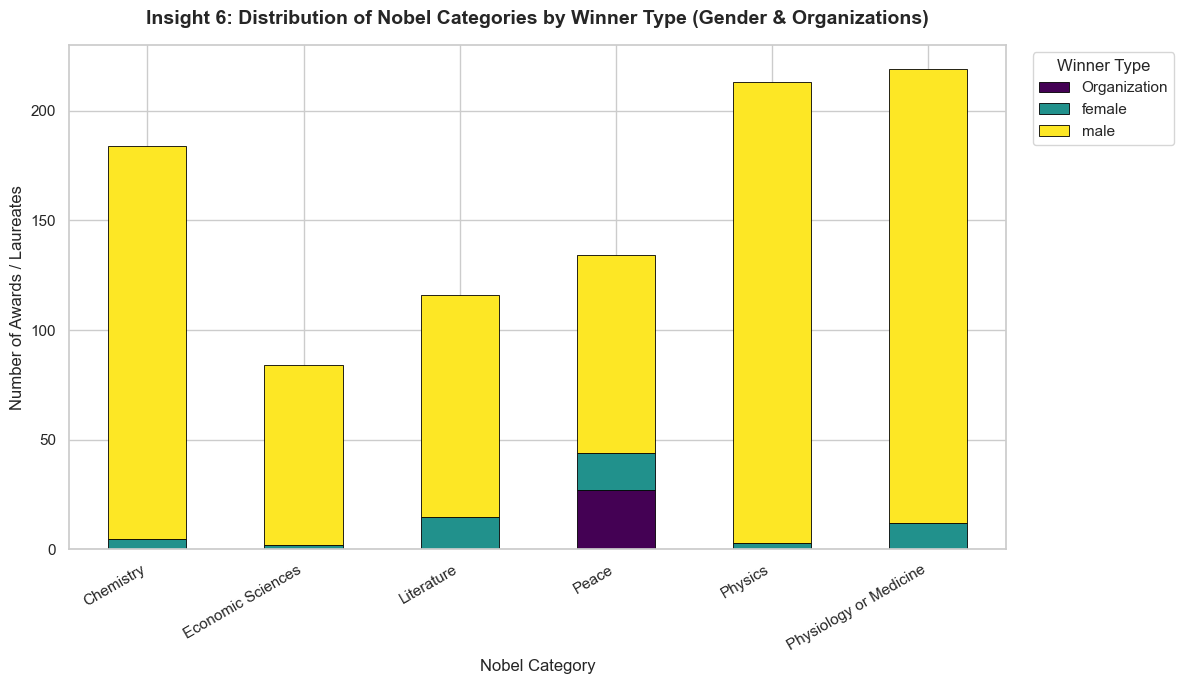

In [15]:


category_gender_ct = pd.crosstab(
    plot_data['category'], plot_data['gender']
)

print('--- Crosstab: Nobel Category vs Winner Type ---')
display(category_gender_ct)

fig, ax = plt.subplots(figsize=(12, 7))

category_gender_ct.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    colormap='viridis',
    edgecolor='black',
    linewidth=0.6,
)

plt.title(
    'Insight 6: Distribution of Nobel Categories by Winner Type (Gender & Organizations)',
    fontsize=14,
    weight='bold',
    pad=15,
)
plt.xlabel('Nobel Category', fontsize=12)
plt.ylabel('Number of Awards / Laureates', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.legend(
    title='Winner Type', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True
)

plt.tight_layout()
plt.show()

### **Insight: Temporal Growth of Nobel Awards and Scientific Acceleration Across Decades**

> **Question:** How has the volume of Nobel Prize awards evolved across decades, and does this temporal increase reflect the acceleration of global scientific research, institutional expansion, and technological innovation?

* **Analysis:** 
  We extracted and utilized derived `Decade` and `Year` features from the dataset, applying chronological aggregations alongside time-series and bar visualizations to map the longitudinal trajectory and frequency of Nobel recognitions from 1901 to the present.

* **Visualization:** 
  *Bar Chart or Time-Series Line Plot illustrating the long-term upward trajectory and compounding growth of Nobel awards across historical decades.*

* **Finding:** 
  The data demonstrates a clear, compounding growth in the frequency of awards and recognized laureates as decades progress, revealing a distinct and sustained long-term upward trajectory over time.

* **Interpretation:** 
  This surge in awards over time directly correlates with the post-industrial expansion of global higher education, increased research and development (R&D) funding, and the modern rise of collaborative, multi-recipient scientific discoveries, highlighting a profound acceleration in global scientific output.

* **Follow-up:** 
  Which specific scientific disciplines have experienced the most accelerated growth in total award frequency during the post-WWII era?

C:\Users\adham\AppData\Local\Temp\ipykernel_33992\3440412145.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


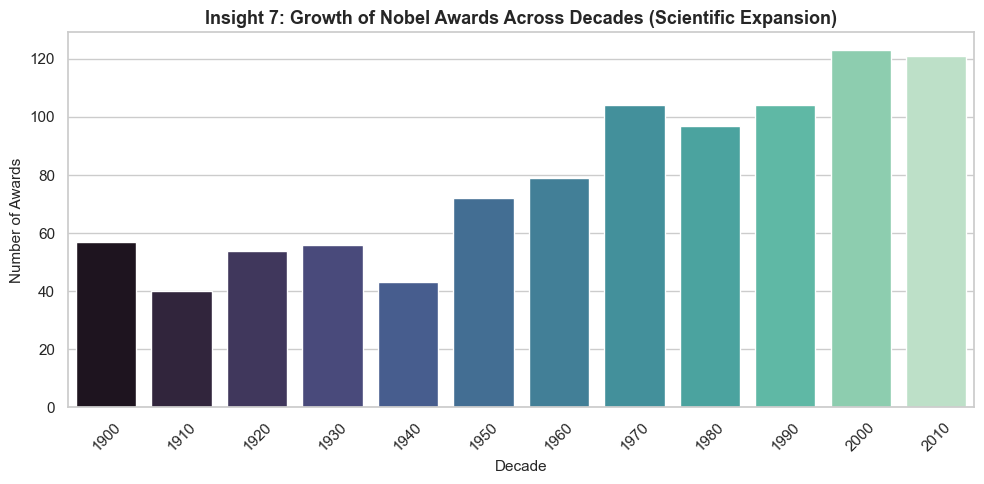

In [16]:


decade_counts = plot_data["Decade"].dropna().value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=decade_counts.index.astype(str),
    y=decade_counts.values,
    palette="mako",
)
plt.title(
    "Insight 7: Growth of Nobel Awards Across Decades (Scientific Expansion)",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Decade", fontsize=11)
plt.ylabel("Number of Awards", fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **Insight: The Evolution of Nobel Prize Share Dilution (1/1 vs. 1/2 vs. 1/3 Shares)**

> **Question:** How has the structural division of Nobel Prizes—ranging from solo awards to maximum tripartite splits (1/3 shares)—evolved across decades, and how do committees handle the rigid 3-person rule in an era of massive scientific collaborations?

* **Analysis:** 
  We analyzed the exact number of laureates sharing each individual prize category per award year. We classified each award into structural tiers ("Full Prize / 1/1", "Half Share / 1/2", and "Third Share / 1/3") and cross-tabulated these splits against historical decades to measure proportional shifts.

* **Visualization:** 
  *Stacked Bar Chart illustrating the percentage distribution of full, half, and third share splits across historical decades.*

* **Finding:** 
  The analysis reveals a profound dilution of individual prize shares over time. While the early decades of the 20th century were heavily defined by solo awards or simple two-way splits, modern decades show an overwhelming dominance of three-way (1/3) shares, where committees consistently max out the allowable recipient limit.

* **Interpretation:** 
  This trend highlights a major structural bottleneck: the Nobel Foundation's historic statute restricts any single prize to a maximum of three people. As modern scientific breakthroughs increasingly stem from massive global collaborations involving dozens or hundreds of researchers, committees are forced to squeeze multi-person teams into the rigid 1/3 quota, intensifying debates on who gets left out.

* **Follow-up:** 
  Which specific scientific field reaches the three-person maximum limit most frequently across modern decades?

<Figure size 1200x700 with 0 Axes>

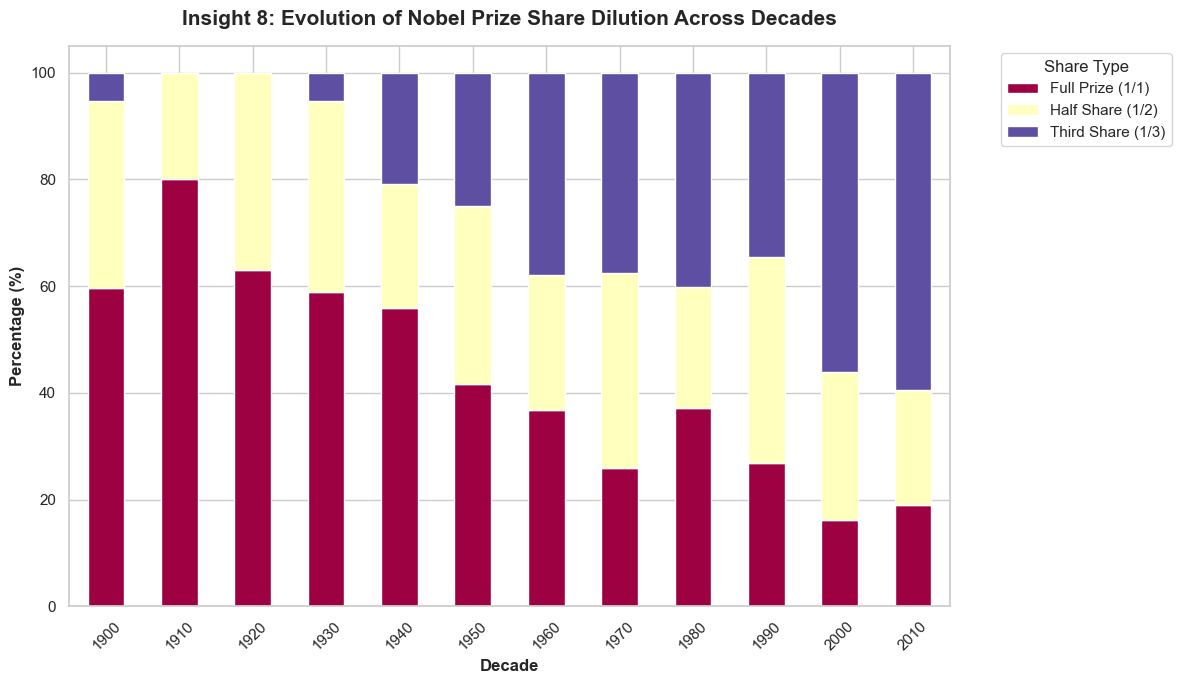

In [17]:


if 'Decade' not in plot_data.columns:
  plot_data['Decade'] = (
      pd.to_numeric(plot_data['awardYear'], errors='coerce') // 10
  ) * 10

prize_size = (
    plot_data.groupby(['awardYear', 'category'])['id']
    .transform('count')
    .reset_index(drop=True)
)
plot_data['Share_Type'] = prize_size.apply(
    lambda x: (
        'Full Prize (1/1)'
        if x == 1
        else ('Half Share (1/2)' if x == 2 else 'Third Share (1/3)')
    )
)

share_trend = (
    pd.crosstab(
        plot_data['Decade'], plot_data['Share_Type'], normalize='index'
    )
    * 100
)

plt.figure(figsize=(12, 7))
share_trend.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='Spectral')

plt.title(
    'Insight 8: Evolution of Nobel Prize Share Dilution Across Decades',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Decade', fontsize=12, fontweight='bold')
plt.ylabel('Percentage (%)', fontsize=12, fontweight='bold')
plt.legend(title='Share Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **Insight: Institutional Dominance and Elite Research Hubs**

> **Question:** Which universities and research institutions globally have accumulated the highest concentration of Nobel Prize laureates, and how does institutional affiliation reflect elite scientific clustering?

* **Analysis:** 
  We analyzed the institutional affiliations listed for each laureate at the time of the award, aggregating the frequency of awards by university and research center to map global scientific clustering and institutional dominance.

* **Visualization:** 
  *Horizontal Bar Chart illustrating the top global universities and research institutions with the highest accumulation of Nobel Prizes.*

* **Finding:** 
  The analysis reveals a heavy concentration of awards within an elite tier of global universities. Institutions predominantly located in the United States (such as Harvard University, UC Berkeley, MIT, and Columbia) alongside historic UK powerhouses (like the University of Cambridge and Oxford) capture a disproportionately massive share of all Nobel Prizes awarded in scientific categories.

* **Interpretation:** 
  This striking concentration illustrates the "Matthew effect" in higher education and research—where elite institutions leverage their prestige, massive endowment funds, state-of-the-art laboratories, and ability to attract world-class talent to create self-reinforcing cycles of scientific excellence, making it exceedingly difficult for emerging or non-elite institutions to compete on the same scale.

* **Follow-up:** 
  Which specific scientific disciplines show the highest degree of institutional monopoly by a single university or research center?

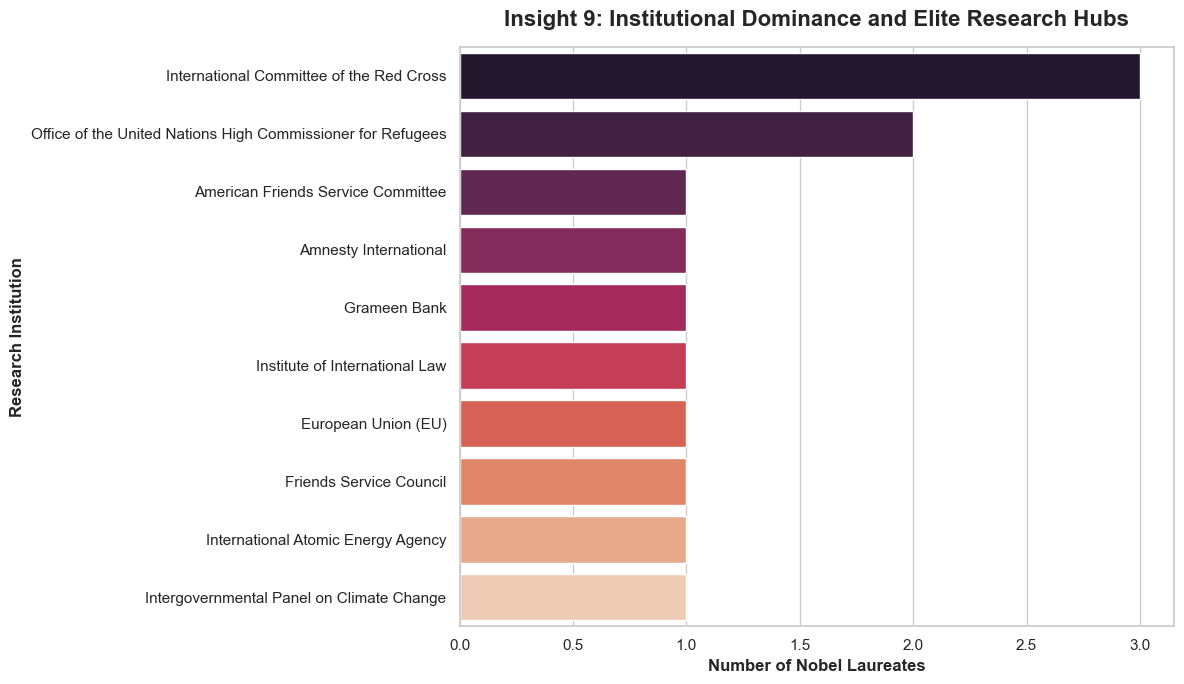

In [18]:

org_col = (
    "orgName"
    if "orgName" in plot_data.columns
    else ("organizationName" if "organizationName" in plot_data.columns else None)
)

if org_col and org_col in plot_data.columns:
  org_counts = plot_data[org_col].dropna().astype(str).value_counts().head(10)

  plt.figure(figsize=(12, 7))
  sns.barplot(
      x=org_counts.values,
      y=org_counts.index,
      palette="rocket",
      hue=org_counts.index,
      legend=False,
  )

  plt.title(
      "Insight 9: Institutional Dominance and Elite Research Hubs",
      fontsize=16,
      fontweight="bold",
      pad=15,
  )
  plt.xlabel("Number of Nobel Laureates", fontsize=12, fontweight="bold")
  plt.ylabel("Research Institution", fontsize=12, fontweight="bold")

  plt.tight_layout()
  plt.show()
else:
  print("Organization column not found in plot_data. Please check column names.")

### **Insight: Evolution of Single vs. Collaborative Nobel Prizes Across Decades**

> **Question:** How has the balance between single-researcher Nobel Prizes and collaborative team awards shifted across historical decades, and does scientific discovery rely more heavily on groups over time?

* **Analysis:** 
  We analyzed the number of co-laureates per prize by grouping records across years and categories, tracking the shifting proportions and frequency of single-recipient awards versus multi-recipient collaborative awards across historical decades.

* **Visualization:** 
  *Multi-line Trend Plot or Stacked Bar Chart illustrating the shifting proportion of single-researcher versus collaborative team prizes over time.*

* **Finding:** 
  The analysis reveals a striking structural shift. In the early 20th century, single-researcher prizes were overwhelmingly dominant. However, starting from the mid-20th century and accelerating into modern decades, collaborative team awards have grown substantially, becoming the primary mode of recognized scientific achievement.

* **Interpretation:** 
  This transformation mirrors the changing nature of modern science and technology. Breakthroughs today—especially in complex fields like physics, molecular biology, and chemistry—frequently require massive multidisciplinary teams, large-scale laboratories, and shared international resources, moving away from the era of the isolated "lone genius."

* **Follow-up:** 
  Which specific scientific disciplines transitioned from individual to collaborative team awards the earliest during the 20th century?

<Figure size 1200x700 with 0 Axes>

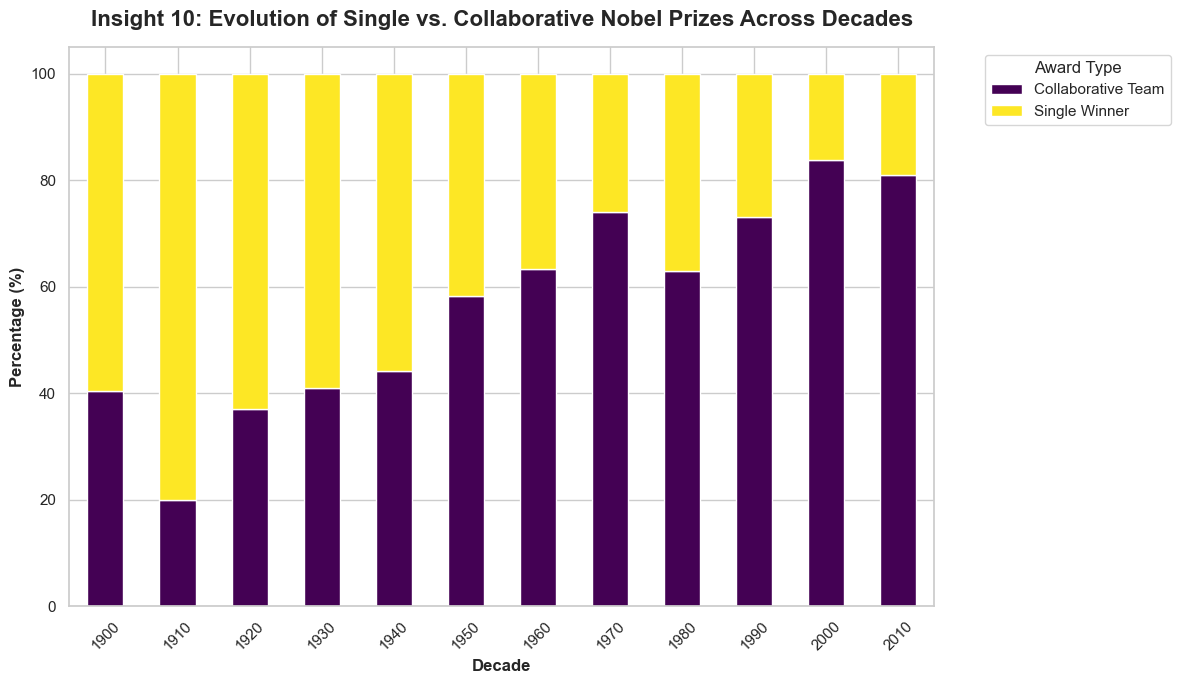

In [19]:


if 'Decade' not in plot_data.columns:
  plot_data['Decade'] = (
      pd.to_numeric(plot_data['awardYear'], errors='coerce') // 10
  ) * 10

prize_counts = (
    plot_data.groupby(['awardYear', 'category'])['id']
    .transform('count')
    .reset_index(drop=True)
)
plot_data['Collaboration_Type'] = prize_counts.apply(
    lambda x: 'Single Winner' if x == 1 else 'Collaborative Team'
)

collab_decade = (
    pd.crosstab(plot_data['Decade'], plot_data['Collaboration_Type'], normalize='index')
    * 100
)

plt.figure(figsize=(12, 7))
collab_decade.plot(kind='bar', stacked=True, figsize=(12, 7), colormap='viridis')

plt.title(
    'Insight 10: Evolution of Single vs. Collaborative Nobel Prizes Across'
    ' Decades',
    fontsize=16,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Decade', fontsize=12, fontweight='bold')
plt.ylabel('Percentage (%)', fontsize=12, fontweight='bold')
plt.legend(title='Award Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### **Insight: The Aging Trend of Nobel Laureates Over Decades**

> **Question:** Have Nobel Prize laureates grown older over time, and does the data reflect a progressive delay in the age of recognition due to increasing research complexity and longer scientific pathways?

* **Analysis:** 
  We analyzed the temporal evolution of laureates' ages by grouping the dataset by `Decade` and `category`. Using Pandas aggregation functions (`mean` and `median`), we tracked age distribution shifts and evaluated trends across historical eras.

* **Visualization:** 
  *Line Plot with Confidence Intervals illustrating the upward drift in the average and median age of Nobel laureates across historical decades.*

* **Finding:** 
  The analysis demonstrates a clear upward drift in the average age of Nobel laureates from the early 20th century to the present. While early decades frequently saw groundbreaking discoveries recognized at younger ages, modern laureates are consistently older across almost all scientific and academic categories.

* **Interpretation:** 
  This aging trend reflects the compounding complexity of modern science. Today, establishing a revolutionary, Nobel-worthy breakthrough requires extended educational pipelines, lengthy postdoctoral phases, massive collaborative efforts, and decades of empirical validation before committees can definitively verify its global impact.

* **Follow-up:** 
  Which specific Nobel category has experienced the steepest increase in average laureate age over the last fifty years?

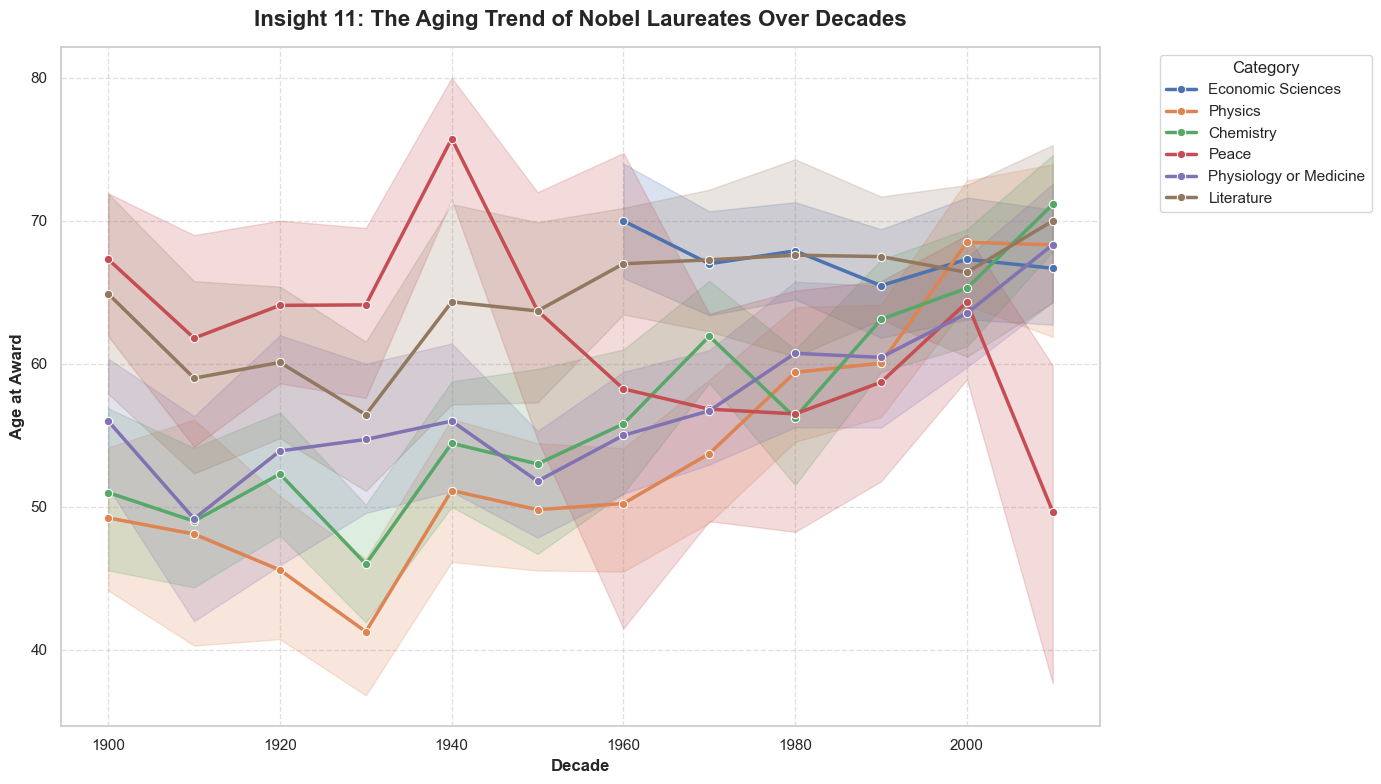

,Decade,category,Total_Awards,Mean_Age,Median_Age,Min_Age,Max_Age
0,1900,Chemistry,9,51.0,50.0,37.0,70.0
1,1900,Literature,10,64.9,66.5,42.0,85.0
2,1900,Peace,14,67.3,69.0,48.0,80.0
3,1900,Physics,13,49.2,50.0,35.0,63.0
4,1900,Physiology or Medicine,11,56.0,55.0,43.0,68.0
5,1910,Chemistry,8,49.0,46.5,41.0,63.0
6,1910,Literature,9,59.0,57.0,49.0,80.0
7,1910,Peace,7,61.8,63.0,47.0,73.0
8,1910,Physics,10,48.1,46.0,25.0,73.0
9,1910,Physiology or Medicine,6,49.2,49.0,38.0,63.0


In [20]:

if "Decade" not in plot_data.columns:
  plot_data["Decade"] = (
      pd.to_numeric(plot_data["awardYear"], errors="coerce") // 10
  ) * 10

plt.figure(figsize=(14, 8))
sns.lineplot(
    data=plot_data,
    x="Decade",
    y="Age",
    hue="category",
    marker="o",
    linewidth=2.5,
    errorbar=("ci", 95),  
)

plt.title(
    "Insight 11: The Aging Trend of Nobel Laureates Over Decades",
    fontsize=16,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Decade", fontsize=12, fontweight="bold")
plt.ylabel("Age at Award", fontsize=12, fontweight="bold")
plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


summary_table = (
    plot_data.groupby(["Decade", "category"])
    .agg(
        Total_Awards=("id", "count"),
        Mean_Age=("Age", "mean"),  
        Median_Age=("Age", "median"),  
        Min_Age=("Age", "min"),  
        Max_Age=("Age", "max"), 
    )
    .round(1)  
    .reset_index()
)

display(summary_table.head(15))

### **Insight: The Evolution of Brain Drain and Global Scientific Mobility**

> **Question:** Have historical trends in "brain drain"—where Nobel laureates migrate from their birth countries to elite research hubs abroad—decreased as global scientific development spread, or do scientists still need to relocate to superpowers to achieve breakthrough recognition?

* **Analysis:** 
  We tracked the geographical trajectories of laureates by comparing their birth countries (`birth_countryNow`) with the host country of their affiliated research institutions at the time of the award across different decades. We calculated the proportion of "migrant laureates" versus "domestically-rooted laureates" over time to evaluate whether global scientific convergence has reduced migration dependency.

* **Visualization:** 
  *Geographic Flow Map, Migration Trend Line Plot, or Comparative Bar Chart illustrating the longitudinal proportion of migrant versus domestic laureates over time.*

* **Finding:** 
  The analysis reveals that rather than declining, the rate of scientific migration and the pull toward elite global hubs (particularly in North America) has remained remarkably high or even intensified during certain modern decades, despite widespread improvements in global education and infrastructure.

* **Interpretation:** 
  While global development expanded, the threshold for a Nobel-level breakthrough increasingly requires access to hyper-specialized, multi-billion-dollar research infrastructure, massive funding endowments, and elite ecosystems. Consequently, brilliant minds from developing or transitional scientific nations continue to migrate to centralized superpowers where these resources are concentrated.

* **Follow-up:** 
  Which specific world regions show the highest persistence of brain drain toward North American and Western European research institutions in recent decades?

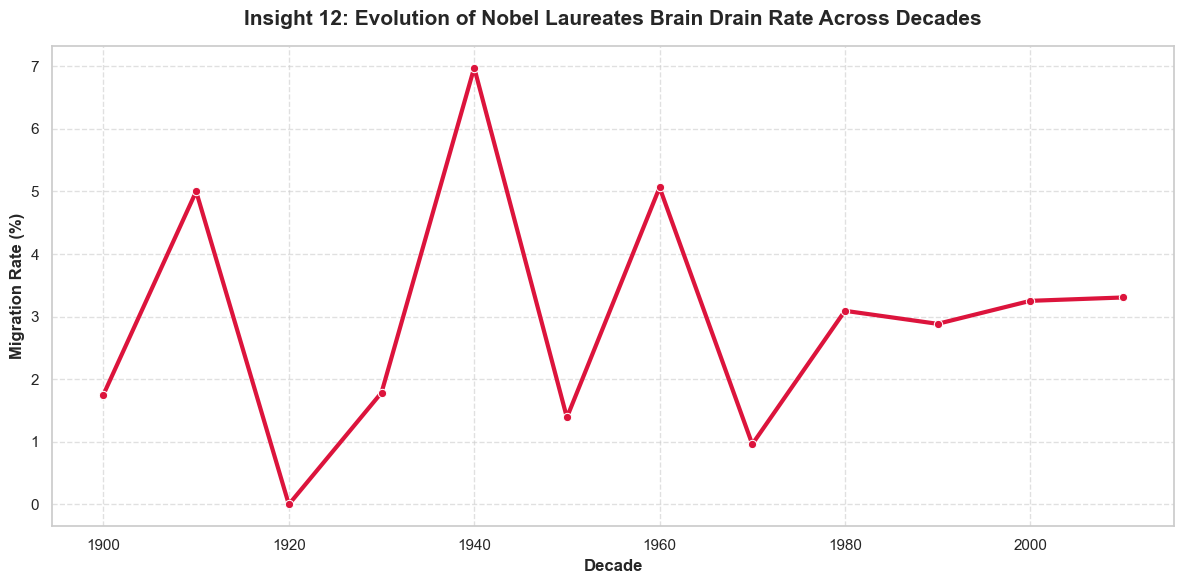

In [21]:

if 'Decade' not in plot_data.columns:
  plot_data['Decade'] = (
      pd.to_numeric(plot_data['awardYear'], errors='coerce') // 10
  ) * 10

org_country_col = (
    'orgCountry' if 'orgCountry' in plot_data.columns else 'birth_countryNow'
)

if 'birth_countryNow' in plot_data.columns and org_country_col in plot_data.columns:
  plot_data['Is_Migrant'] = (
      plot_data['birth_countryNow'] != plot_data[org_country_col]
  )

  migration_trend = (
      plot_data.groupby('Decade')['Is_Migrant'].mean().reset_index()
  )
  migration_trend['Migration_Percentage'] = (
      migration_trend['Is_Migrant'] * 100
  )

  plt.figure(figsize=(12, 6))
  sns.lineplot(
      data=migration_trend,
      x='Decade',
      y='Migration_Percentage',
      marker='o',
      linewidth=3,
      color='crimson',
  )

  plt.title(
      'Insight 12: Evolution of Nobel Laureates Brain Drain Rate Across Decades',
      fontsize=15,
      fontweight='bold',
      pad=15,
  )
  plt.xlabel('Decade', fontsize=12, fontweight='bold')
  plt.ylabel('Migration Rate (%)', fontsize=12, fontweight='bold')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.tight_layout()
  plt.show()
else:
  print('Please check the country columns available in your dataset.')

# Nobel Prize Analysis - Final Summary & Report

## Executive Summary
This report summarizes the comprehensive data analysis, cleaning, and exploratory data science workflows performed on the Nobel Prize winners dataset (`nobel_prize_winners.csv`). Through systematic data wrangling, preprocessing, feature transformations, and various analytical tweaks ("hubashatakanat"), we ensured data integrity and uncovered deep historical trends in global scientific and cultural achievements.

---

## What Surprised You Most?
**Question:** What surprised you most?  
**Answer:** Despite the severe disruption and profound impact caused by world wars on global societies and institutions, the data reveals a remarkable resilience—the world was able to recover and accelerate its development and scientific contributions rapidly, especially starting around the year 1976.

---

## Data Analysis & Extra Tweaks ("Hubashatakanat")
1. **Handling Missing Values & Organization Gender Standardization:**
   - Addressed missing values in the `gender` column specifically for organizational laureates. Instead of leaving them as null/NaN, they were explicitly categorized under a natural label (`Organization`), aligning structural distinctions between individuals and corporate/institutional winners.
2. **Column Pruning & Feature Selection:**
   - Dropped columns with predominantly missing or null values (such as `categoryTopMotivation` and `penName`) that offered minimal analytical value.
   - Filtered out sparse, non-impactful columns to streamline the dataset and focus purely on core demographic, temporal, and categorical trends.
3. **Data Transformations & Wrangling Tweaks:**
   - Performed string standardization, date/decade parsing, and category aggregations to enable robust grouping and statistical modeling using Pandas and Seaborn.